# Chapter 26: A Hotel With No Vacancy

*Math Class Didn't Show Its Work* by Jason Karpeles

**In this notebook you will** follow the chapter's imaginary hotel, where every room is taken and yet more guests can still check in. You will see that the rooms are labels, not walls, and that checking a rule means asking two questions: do two guests ever land in the same room, and is every room accounted for? You will also see why 0.999... and 1 are the same number.

The code cells are optional reading. You can skip them: the results and the pictures are shown right below each one. If you are curious, read a code cell like a recipe, one line at a time. Every number is built from steps you can check with a calculator.

In [1]:
# Setup: numpy and matplotlib only. Nothing here needs to be understood to follow along.
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction
%matplotlib inline

INK, TEAL, TERRA, NAVY, GOLD, GREY, LIGHT = "#222222", "#1b7f79", "#c0562f", "#1f3a5f", "#b8860b", "#777777", "#d9d9d9"
plt.rcParams.update({"figure.figsize": (7.5, 4.2), "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 11, "axes.grid": True, "grid.alpha": 0.25})

def show_fig(title=None):
    if title:
        plt.title(title, fontsize=12)
    plt.tight_layout()
    plt.show()

def draw_rooms(ax, xs, y, labels, faces=None, w=0.84):
    from matplotlib.patches import Rectangle
    for i, (x, lab) in enumerate(zip(xs, labels)):
        face = faces[i] if faces else "white"
        ax.add_patch(Rectangle((x - w / 2, y - 0.32), w, 0.64, facecolor=face, edgecolor=GREY, linewidth=1.2))
        ax.text(x, y, lab, ha="center", va="center", fontsize=10)

## 1. One new guest

**Question in plain words:** Every room is taken. Can one more guest check in without anyone sharing a room or leaving?

**Equation from the chapter:**

$$n \to n + 1 \qquad\text{and if two guests landed together: } a + 1 = b + 1 \text{ forces } a = b$$

**What the symbols mean:** $n$ is a current guest's original room number, and the rule moves that guest to room $n+1$. The letters $a$ and $b$ are two different starting rooms. If they ended in the same room we would have $a + 1 = b + 1$, which forces $a = b$, so two different guests never collide.

In [2]:
print("Rule: the guest in room n moves to room n + 1.")
print()
print("A few guests moving:")
for n in [1, 2, 5, 8]:
    print(f"  guest in room {n} moves to room {n} + 1 = {n + 1}")
print()
print("Who is in room 1 afterwards? Work backward: n + 1 = 1 needs n = 1 - 1 = 0.")
print("  There is no guest 0, so room 1 is free for the new guest.")
print()
print("Who is in room 6? Work backward: 6 - 1 = 5, so original guest 5. Check: 5 + 1 = 6.")
print()
print("No collision: suppose a + 1 = b + 1. Subtract 1 from both sides: a = b. So two different guests never share.")
print()
print("Now a hotel that ends at room 6:")
print("  guest 6 would need room 6 + 1 = 7, and there is no room 7.")

Rule: the guest in room n moves to room n + 1.

A few guests moving:
  guest in room 1 moves to room 1 + 1 = 2
  guest in room 2 moves to room 2 + 1 = 3
  guest in room 5 moves to room 5 + 1 = 6
  guest in room 8 moves to room 8 + 1 = 9

Who is in room 1 afterwards? Work backward: n + 1 = 1 needs n = 1 - 1 = 0.
  There is no guest 0, so room 1 is free for the new guest.

Who is in room 6? Work backward: 6 - 1 = 5, so original guest 5. Check: 5 + 1 = 6.

No collision: suppose a + 1 = b + 1. Subtract 1 from both sides: a = b. So two different guests never share.

Now a hotel that ends at room 6:
  guest 6 would need room 6 + 1 = 7, and there is no room 7.


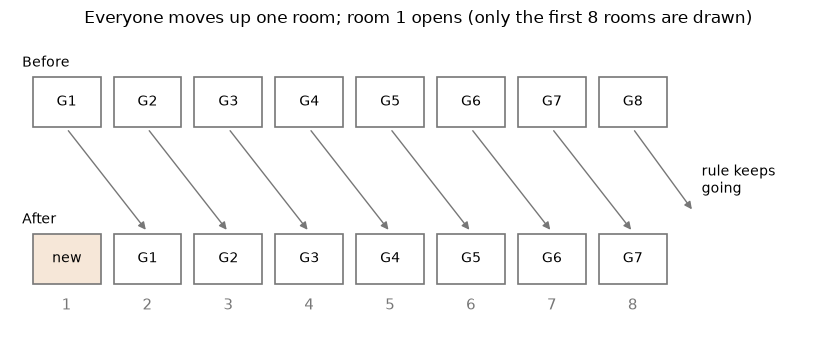

In [3]:
shown = 8
fig, ax = plt.subplots(figsize=(8.5, 3.6))
draw_rooms(ax, range(1, shown + 1), 2.0, [f"G{n}" for n in range(1, shown + 1)])
after = ["new"] + [f"G{r - 1}" for r in range(2, shown + 1)]
draw_rooms(ax, range(1, shown + 1), 0.0, after, faces=["#f6e7d8"] + ["white"] * (shown - 1))
for n in range(1, shown):
    ax.annotate("", xy=(n + 1, 0.34), xytext=(n, 1.66), arrowprops=dict(arrowstyle="-|>", color=GREY))
ax.annotate("", xy=(shown + 0.75, 0.6), xytext=(shown, 1.66), arrowprops=dict(arrowstyle="-|>", color=GREY))
ax.text(shown + 0.85, 1.0, "rule keeps\ngoing", va="center", fontsize=10)
for r in range(1, shown + 1):
    ax.text(r, -0.5, str(r), ha="center", va="top", color=GREY)
ax.text(0.45, 2.45, "Before", fontsize=10)
ax.text(0.45, 0.45, "After", fontsize=10)
ax.set_xlim(0.3, shown + 2.4); ax.set_ylim(-1.0, 2.9)
ax.axis("off")
show_fig("Everyone moves up one room; room 1 opens (only the first 8 rooms are drawn)")

**What this shows.** Every guest moves one room up, so room 1 is left over for the new guest. Working backward from any room $r$ of 2 or more finds guest $r-1$, so no room is skipped. Nothing is evicted, because there is no last guest.

**Where it stops working.** The shift needs rooms labeled 1, 2, 3, ... with no last one. A real building, or any device with a fixed number of slots, has a last room, and the rule fails there: in the 6-room hotel, guest 6 has nowhere to go.

## 2. Any finite number of new guests

**Question in plain words:** If $k$ new guests arrive at once, which rooms open up for them?

**Equations from the chapter:**

$$n \to n + k \qquad k+1,\ k+2,\ k+3,\ \ldots \qquad a + k = b + k$$

**What the symbols mean:** $k$ is the fixed number of new guests, stated first. Old guest $n$ moves to room $n+k$, so old guests land in rooms $k+1, k+2, k+3$, and onward. New guest $j$ takes room $j$, for $j$ from 1 to $k$.

In [4]:
k = 4
print(f"k = {k} new guests. Rule: old guest n moves to room n + {k}.")
print()
for n in [1, 2, 3]:
    print(f"  old guest {n} goes to room {n} + {k} = {n + k}")
print()
print(f"Rooms 1 through {k} are free, so new guest j takes room j.")
print(f"Room 12 holds: old guest 12 - {k} = {12 - k}")
print(f"No collision: if a + {k} = b + {k}, subtract {k} from both sides and a = b.")
print()
print("Other values of k from the reader's menu, and who sits in room 12:")
for kk in [1, 3, 4, 7]:
    print(f"  k = {kk}: old guest 1 goes to room 1 + {kk} = {1 + kk};  room 12 holds old guest 12 - {kk} = {12 - kk}")

k = 4 new guests. Rule: old guest n moves to room n + 4.

  old guest 1 goes to room 1 + 4 = 5
  old guest 2 goes to room 2 + 4 = 6
  old guest 3 goes to room 3 + 4 = 7

Rooms 1 through 4 are free, so new guest j takes room j.
Room 12 holds: old guest 12 - 4 = 8
No collision: if a + 4 = b + 4, subtract 4 from both sides and a = b.

Other values of k from the reader's menu, and who sits in room 12:
  k = 1: old guest 1 goes to room 1 + 1 = 2;  room 12 holds old guest 12 - 1 = 11
  k = 3: old guest 1 goes to room 1 + 3 = 4;  room 12 holds old guest 12 - 3 = 9
  k = 4: old guest 1 goes to room 1 + 4 = 5;  room 12 holds old guest 12 - 4 = 8
  k = 7: old guest 1 goes to room 1 + 7 = 8;  room 12 holds old guest 12 - 7 = 5


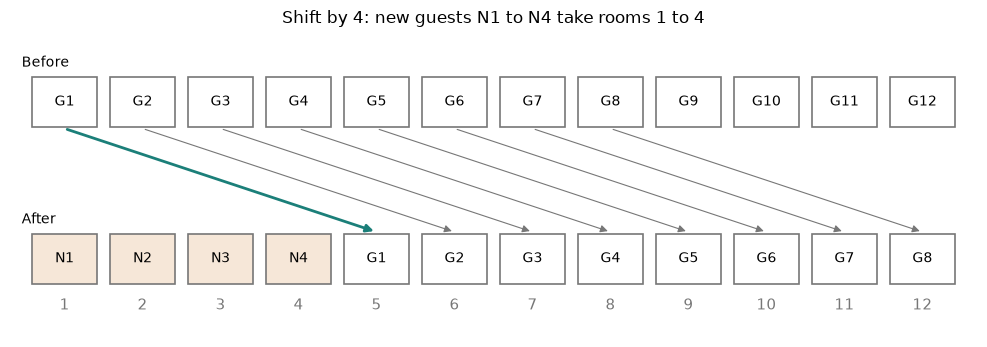

In [5]:
shown = 12
fig, ax = plt.subplots(figsize=(10, 3.6))
draw_rooms(ax, range(1, shown + 1), 2.0, [f"G{n}" for n in range(1, shown + 1)])
after = [f"N{r}" if r <= k else f"G{r - k}" for r in range(1, shown + 1)]
faces = ["#f6e7d8" if r <= k else "white" for r in range(1, shown + 1)]
draw_rooms(ax, range(1, shown + 1), 0.0, after, faces=faces)
for n in range(1, shown - k + 1):
    ax.annotate("", xy=(n + k, 0.34), xytext=(n, 1.66),
                arrowprops=dict(arrowstyle="-|>", color=TEAL if n == 1 else GREY, lw=2 if n == 1 else 0.8))
for r in range(1, shown + 1):
    ax.text(r, -0.5, str(r), ha="center", va="top", color=GREY)
ax.text(0.45, 2.45, "Before", fontsize=10); ax.text(0.45, 0.45, "After", fontsize=10)
ax.set_xlim(0.3, shown + 0.7); ax.set_ylim(-1.0, 2.9)
ax.axis("off")
show_fig(f"Shift by {k}: new guests N1 to N{k} take rooms 1 to {k}")

**What this shows.** Shifting by $k$ leaves rooms 1 through $k$ free. Old guests only use rooms above $k$, so they never collide with the new guests, and $a + k = b + k$ forces $a = b$.

**Where it stops working.** $k$ must be stated first and stay fixed. The rule is written after $k$ is known; no single shift handles every possible $k$ at once.

## 3. A whole second list of guests

**Question in plain words:** A second endless list of guests arrives. How can everyone get exactly one room?

**Equations from the chapter:**

$$n \to 2n \qquad m \to 2m - 1 \qquad \frac{r}{2} \qquad \frac{r+1}{2}$$

**What the symbols mean:** Old guest $n$ goes to room $2n$ (an even room). New guest $m$ goes to room $2m - 1$ (an odd room). Working backward: even room $r$ holds old guest $r/2$, and odd room $r$ holds new guest $(r+1)/2$. Both lists start at 1, so the tags *old* and *new* stay attached to each number.

In [6]:
r = 17
print("Plan: old guest n goes to room 2n; new guest m goes to room 2m - 1.")
print()
print(f"Who is in room {r}?")
print(f"  {r} is {'even' if r % 2 == 0 else 'odd'}.")
if r % 2 == 1:
    m = (r + 1) // 2
    print(f"  new guest (r + 1)/2 = ({r} + 1)/2 = {r + 1}/2 = {m}")
    print(f"  Check: 2m - 1 = 2({m}) - 1 = {2 * m} - 1 = {2 * m - 1}")
print()
print("Trace more rooms from the reader's menu:")
for room in [17, 8, 3]:
    if room % 2 == 0:
        print(f"  room {room} is even: old guest {room}/2 = {room // 2}   (check 2 x {room // 2} = {room})")
    else:
        print(f"  room {room} is odd: new guest ({room} + 1)/2 = {(room + 1) // 2}   (check 2 x {(room + 1) // 2} - 1 = {room})")
print()
print("The broken plan: send BOTH lists to room 2n.")
for room in [8, 17]:
    if room % 2 == 0:
        print(f"  room {room}: old guest {room // 2} and new guest {room // 2} both land here (2 x {room // 2} = {room}). Collision.")
    else:
        print(f"  room {room}: nobody (2 x {room // 2} + 1 = {room} is odd, and 2n is always even). Empty.")

Plan: old guest n goes to room 2n; new guest m goes to room 2m - 1.

Who is in room 17?
  17 is odd.
  new guest (r + 1)/2 = (17 + 1)/2 = 18/2 = 9
  Check: 2m - 1 = 2(9) - 1 = 18 - 1 = 17

Trace more rooms from the reader's menu:
  room 17 is odd: new guest (17 + 1)/2 = 9   (check 2 x 9 - 1 = 17)
  room 8 is even: old guest 8/2 = 4   (check 2 x 4 = 8)
  room 3 is odd: new guest (3 + 1)/2 = 2   (check 2 x 2 - 1 = 3)

The broken plan: send BOTH lists to room 2n.
  room 8: old guest 4 and new guest 4 both land here (2 x 4 = 8). Collision.
  room 17: nobody (2 x 8 + 1 = 17 is odd, and 2n is always even). Empty.


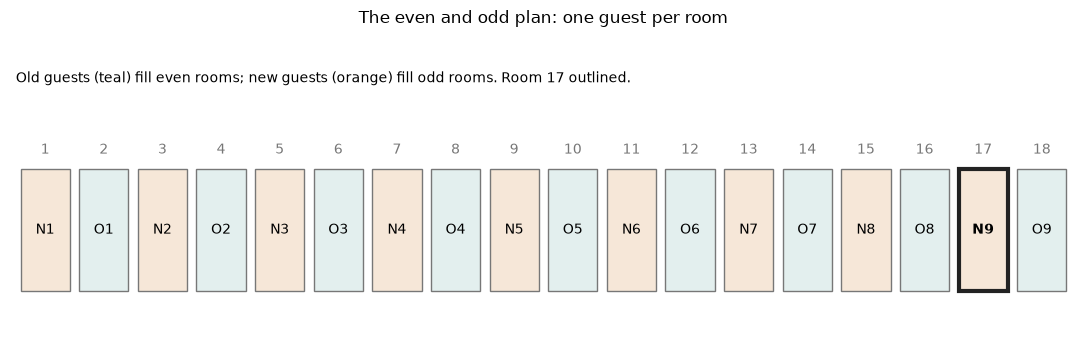

In [7]:
from matplotlib.patches import Rectangle
shown = 18
half = shown // 2
occ = {x: [] for x in range(1, shown + 1)}
for n in range(1, half + 1):
    occ[2 * n].append(f"O{n}")
for m in range(1, half + 1):
    occ[2 * m - 1].append(f"N{m}")
fig, ax = plt.subplots(figsize=(11, 3.6))
for x in range(1, shown + 1):
    traced = x == 17
    face = "#e3efee" if occ[x][0].startswith("O") else "#f6e7d8"
    ax.add_patch(Rectangle((x - 0.42, 0.45), 0.84, 1.2, facecolor=face, edgecolor=INK if traced else GREY,
                           linewidth=3 if traced else 1))
    ax.text(x, 1.05, occ[x][0], ha="center", va="center", fontsize=10, fontweight="bold" if traced else "normal")
    ax.text(x, 1.8, str(x), ha="center", color=GREY, fontsize=10)
ax.text(0.5, 2.5, "Old guests (teal) fill even rooms; new guests (orange) fill odd rooms. Room 17 outlined.", fontsize=10)
ax.set_xlim(0.4, shown + 0.6); ax.set_ylim(0, 3)
ax.axis("off")
show_fig("The even and odd plan: one guest per room")

**What this shows.** Every whole number is even or odd and never both, so the two lists never collide, and every room is used. Merging two numbered lists works by giving each list its own class of numbers, then testing the merge by recovering where any combined number came from.

**Where it stops working.** Both lists must be countable and labeled 1, 2, 3, .... A plan that sends both lists to the same class collides, as the broken plan above shows.

## 4. Why 0.999... is 1

**Question in plain words:** Every truncation of 0.999... (0.9, 0.99, 0.999, ...) is below 1. Does that leave a tiny gap at the end?

**Equations from the chapter:**

$$1 - 10^{-n} \qquad 0.999\ldots = 1$$

**What the symbols mean:** $n$ counts the nines written so far. The truncation with $n$ nines equals $1 - 10^{-n}$, so its gap from 1 is one tenth, one hundredth, one thousandth, and so on.

In [8]:
from fractions import Fraction

def nines_text(k):
    return "0." + "9" * k

def gap_text(k):
    return "0." + "0" * (k - 1) + "1"

nines, tolerance = 3, Fraction("0.01")
gap = Fraction(1, 10 ** nines)
print(f"Truncation with {nines} nines: {nines_text(nines)}")
print(f"Gap from 1: 1 - {nines_text(nines)} = {gap_text(nines)}, which is 10 to the power -{nines}")
print(f"Is {gap_text(nines)} below the requested gap 0.01? {'yes' if gap < tolerance else 'not yet'}")
needed = next(k for k in range(1, 30) if Fraction(1, 10 ** k) < tolerance)
print(f"First stage with a gap below 0.01: {needed} nines (gap {gap_text(needed)})")
print()
print("Each extra nine makes the gap ten times smaller:")
for k in range(1, 7):
    print(f"  {k} nine{'s' if k > 1 else ' '}: 1 - {nines_text(k)} = {gap_text(k)}")
print()
print("Other choices from the reader's menu:")
for nn in [1, 2, 3, 6]:
    g = Fraction(1, 10 ** nn)
    for tol in ["0.01", "0.00001"]:
        t = Fraction(tol)
        first = next(k for k in range(1, 30) if Fraction(1, 10 ** k) < t)
        print(f"  {nn} nine(s), requested gap {tol}: gap {gap_text(nn)} is {'below' if g < t else 'not yet below'}; first stage is {first} nines")

Truncation with 3 nines: 0.999
Gap from 1: 1 - 0.999 = 0.001, which is 10 to the power -3
Is 0.001 below the requested gap 0.01? yes
First stage with a gap below 0.01: 3 nines (gap 0.001)

Each extra nine makes the gap ten times smaller:
  1 nine : 1 - 0.9 = 0.1
  2 nines: 1 - 0.99 = 0.01
  3 nines: 1 - 0.999 = 0.001
  4 nines: 1 - 0.9999 = 0.0001
  5 nines: 1 - 0.99999 = 0.00001
  6 nines: 1 - 0.999999 = 0.000001

Other choices from the reader's menu:
  1 nine(s), requested gap 0.01: gap 0.1 is not yet below; first stage is 3 nines
  1 nine(s), requested gap 0.00001: gap 0.1 is not yet below; first stage is 6 nines
  2 nine(s), requested gap 0.01: gap 0.01 is not yet below; first stage is 3 nines
  2 nine(s), requested gap 0.00001: gap 0.01 is not yet below; first stage is 6 nines
  3 nine(s), requested gap 0.01: gap 0.001 is below; first stage is 3 nines
  3 nine(s), requested gap 0.00001: gap 0.001 is not yet below; first stage is 6 nines
  6 nine(s), requested gap 0.01: gap 0.00000

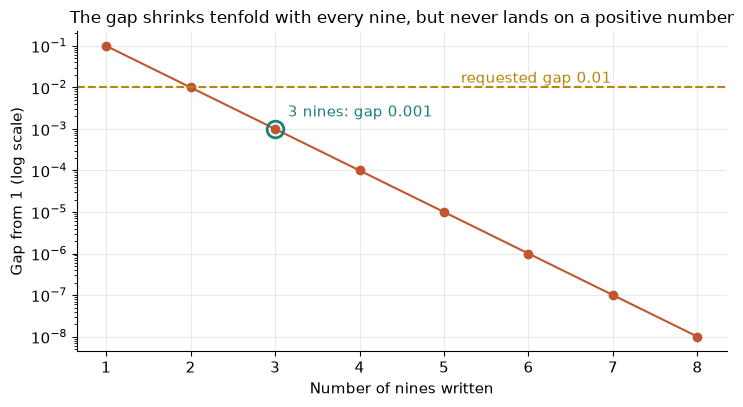

In [9]:
ks = np.arange(1, 9)
fig, ax = plt.subplots()
ax.semilogy(ks, 10.0 ** (-ks), "o-", color=TERRA)
ax.axhline(0.01, color=GOLD, linestyle="dashed")
ax.text(5.2, 0.013, "requested gap 0.01", color=GOLD)
ax.plot([3], [1e-3], "o", markersize=12, markerfacecolor="none", markeredgecolor=TEAL, markeredgewidth=2)
ax.text(3.15, 2e-3, "3 nines: gap 0.001", color=TEAL)
ax.set_xlabel("Number of nines written")
ax.set_ylabel("Gap from 1 (log scale)")
show_fig("The gap shrinks tenfold with every nine, but never lands on a positive number")

**What this shows.** Any positive gap you name is beaten at some stage and stays beaten, because each extra nine divides the gap by 10. No positive gap survives the endless string, so $0.999\ldots = 1$. The same reasoning shows $0.4999\ldots = 0.5$: check the numbers two digit strings name before deciding they are different.

**Where it stops working.** An infinite decimal names the limit of its finite truncations. Only finite stages are ever drawn. Reading 0.999... as a list that stops somewhere would bring the gap back, and that misreads the notation.

## Practice

**1.** Under the rule $n \to n + 1$, which original guest ends up in room 40?

<details><summary>Show answer</summary>

Work backward: $40 - 1 = 39$, so original guest 39. Check: $39 + 1 = 40$.

</details>

**2.** If $k = 4$, which rooms are free, and where does old guest 3 go?

<details><summary>Show answer</summary>

Rooms 1 through 4 are free. Old guest 3 goes to room $3 + 4 = 7$.

</details>

**3.** In the even and odd plan, who is in room 31?

<details><summary>Show answer</summary>

31 is odd, so it holds new guest $(31 + 1)/2 = 32/2 = 16$. Check: $2 \times 16 - 1 = 32 - 1 = 31$.

</details>

**4.** How many nines make the gap from 1 smaller than 0.0001?

<details><summary>Show answer</summary>

Four nines: $1 - 0.9999 = 0.0001$, which is equal to 0.0001, not below it. Five nines: $1 - 0.99999 = 0.00001$, which is below 0.0001. So five nines.

</details>